# Day 8 — XGBoost and provisional model-family selection

Random Forest is the provisional validation leader; unweighted Logistic Regression remains the baseline. We now test a compact, predeclared boosted-tree candidate set.

Random Forest averages independently trained bootstrap trees, primarily reducing variance. Gradient boosting adds trees sequentially to improve the current ensemble's objective, allowing shallow trees to combine into nonlinear relationships and interactions. XGBoost may capture changing activity and recency patterns that an additive logistic model misses. This flexibility also creates overfitting risk. Learning rate controls each tree's contribution: smaller rates usually need more rounds; deeper trees make each round more flexible, so depth and rate must be considered together. Child-weight, L1/L2 penalties, split penalties and row/column sampling constrain complexity.

The same approved temporal evaluation stays primary. **Test remains sealed. No calibration, SHAP, resampling or operational threshold selection is performed.**

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/features.py').exists(): ROOT = ROOT.parent
assert (ROOT / 'src/features.py').exists(), 'Run from root or notebooks/'
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import joblib, sklearn, xgboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from src.features import TARGET_COLUMN, PREDICTOR_COLUMNS
from src.preprocessing import (validate_model_panel, temporal_split_labels, predictor_frame,
                               build_xgboost_pipeline, NUMERIC_COLUMNS)
from src.modelling import modelling_partition, guarded_probabilities, evaluate_candidate
from src.boosting import XGB_CANDIDATES, PARAMETER_COLUMNS, validate_candidate_results, select_xgboost_candidate
from src.evaluation import classification_metrics, ranking_metrics, cumulative_gains_table, threshold_analysis
REPORTS, FIGURES, MODELS = ROOT/'reports', ROOT/'reports/figures', ROOT/'models'
for directory in [REPORTS, FIGURES, MODELS]: directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / ('xgboost_' + name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
print('Python', platform.python_version(), 'XGBoost', xgboost.__version__, 'sklearn', sklearn.__version__)

Python 3.13.2 XGBoost 3.4.1 sklearn 1.9.1


## Data, metadata exclusion and temporal protection

TRAIN: 2005-03-31–2005-12-31; January–February 2006 embargo.
VALIDATION: 2006-03-31–2006-05-31; June–July 2006 embargo.
TEST: 2006-08-31–2006-11-30.

Only test row count, snapshot dates and known target prevalence are reported. No test predictor frame is constructed. Shared guards verify dates before fitting or predicting, and the feature dictionary/ColumnTransformer exclude UserID, snapshot_date and churn_60d from predictors. The untouched test is reserved for one final evaluation after all model-family, calibration and threshold decisions are locked.

In [2]:
data_path = ROOT/'data/processed/model_panel_60d.csv'
panel = pd.read_csv(data_path, parse_dates=['snapshot_date'])
validate_model_panel(panel)
labels = temporal_split_labels(panel.snapshot_date)
split_summary = pd.DataFrame([
    {'split': split, 'row_count': int(labels.eq(split).sum()),
     'snapshot_dates': ', '.join(panel.loc[labels.eq(split), 'snapshot_date'].dt.strftime('%Y-%m-%d').sort_values().unique()),
     'churn_prevalence': panel.loc[labels.eq(split), TARGET_COLUMN].mean()}
    for split in ['train', 'embargo', 'validation', 'test']])
display(split_summary)
split_summary.to_csv(REPORTS/'xgboost_split_summary.csv', index=False)
train, validation = modelling_partition(panel, 'train'), modelling_partition(panel, 'validation')
del panel, labels
X_train, y_train = predictor_frame(train), train[TARGET_COLUMN]
X_validation, y_validation = predictor_frame(validation), validation[TARGET_COLUMN]
assert not {'UserID', 'snapshot_date', TARGET_COLUMN}.intersection(X_train.columns)
assert len(train) == 10380 and len(validation) == 2184

,split,row_count,snapshot_dates,churn_prevalence
0,train,10380,"2005-03-31, 2005-04-30, 2005-05-31, 2005-06-30...",0.360886
1,embargo,3070,"2006-01-31, 2006-02-28, 2006-06-30, 2006-07-31",0.365147
2,validation,2184,"2006-03-31, 2006-04-30, 2006-05-31",0.353938
3,test,2838,"2006-08-31, 2006-09-30, 2006-10-31, 2006-11-30",0.340733


## Train-only preprocessing and predeclared candidate design

Country, Language and Gender use most-frequent imputation and one-hot encoding (`handle_unknown="ignore"`). Numerical features use median imputation with missingness indicators. Everything is fitted on TRAIN inside the pipeline. Tree split ordering does not require scaling. The ColumnTransformer emits a dense matrix so legitimate zeros remain zeros; XGBoost treats implicit sparse entries as missing.

All ten candidates use binary logistic objective, logloss evaluation setting, histogram trees, seed 42, `n_jobs=-1`, gain reference importance and no class reweighting. Prevalence near 36% does not call for automatic weighting. No eval_set or early stopping is used: every candidate fits its fixed round count using TRAIN only, making validation's role explicit.

The initial model is shallow with a small rate and substantial regularization. Slow-long isolates more rounds; shallow rate variants explore the rate/round tradeoff; moderate and regularized depth-4 variants compare flexibility; depth-5 variants contrast regularized and flexible fits. Full sampling and stronger column sampling examine ensemble diversity. The entire table is fixed before fitting; there is no adaptive follow-up search.

**Candidate selection rule:** apply Day 7's sequential near-tie tolerances: retain models within 0.002 of best validation AP, 0.002 ROC-AUC, 0.02 Lift@10%, 0.002 Recall@10%, then within 0.02 of the smallest AP generalization gap and 0.002 of the lowest Brier. Among remaining ties prefer shallower depth, greater child weight, larger lambda/alpha/gamma, then fewer trees. These absolute tolerances are pragmatic, not significance tests. Accuracy is diagnostic only.

**Family recommendation rule:** apply the same AP/ROC/lift/recall tolerances across the three selected family representatives. Within ranking ties prefer lower AP gap among RF/XGBoost (0.02 tolerance), then lower Brier (0.002). If Logistic Regression remains tied, prefer its simplicity; otherwise prefer RF on a remaining family tie. Large gaps are discussed even when ranking wins. The recommendation uses multiple criteria and is provisional until the final locked test evaluation.

In [3]:
display(pd.DataFrame(XGB_CANDIDATES))
pipelines, candidate_rows = {}, []
for config in XGB_CANDIDATES:
    print('Fitting', config['name'], flush=True)
    start = time.perf_counter()
    pipeline = build_xgboost_pipeline(**{k: config[k] for k in PARAMETER_COLUMNS})
    metrics = evaluate_candidate(pipeline, train, validation)
    pipelines[config['name']] = pipeline
    candidate_rows.append({**config, **metrics, 'fit_evaluate_seconds': time.perf_counter() - start})
candidate_results = pd.DataFrame(candidate_rows)
validate_candidate_results(candidate_results)
candidate_results.to_csv(REPORTS/'xgboost_candidate_results.csv', index=False)
selected_name = select_xgboost_candidate(candidate_results)
selected = pipelines[selected_name]
selected_record = candidate_results.set_index('name').loc[selected_name]
initial_record = candidate_results.set_index('name').loc['initial_conservative']
display(candidate_results[['name', *PARAMETER_COLUMNS, 'train_roc_auc', 'roc_auc', 'train_average_precision',
                          'average_precision', 'roc_auc_gap', 'average_precision_gap', 'brier_score',
                          'lift_at_top10pct', 'recall_at_top10pct']])
print('Selected candidate:', selected_name)
display(Markdown('### Initial conservative model: train and validation'))
display(initial_record.to_frame('initial'))
del pipelines, pipeline
pre = selected['preprocessing']
matrix = pre.transform(X_validation)
assert isinstance(matrix, np.ndarray) and matrix.shape[0] == len(validation) and np.isfinite(matrix).all()
np.testing.assert_allclose(pre.named_transformers_['numeric']['imputer'].statistics_, X_train[NUMERIC_COLUMNS].median())
del matrix

,name,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma
0,initial_conservative,400,0.03,3,10,0.8,0.9,10,0.1,0.1
1,slow_long,800,0.03,3,10,0.8,0.9,10,0.1,0.1
2,shallow_rate05,400,0.05,3,10,0.8,0.9,10,0.1,0.1
3,shallow_rate08,300,0.08,3,5,0.8,0.9,5,0.1,0.0
4,depth4_moderate,500,0.05,4,5,0.8,0.9,5,0.1,0.1
5,depth4_regularized,500,0.05,4,10,0.8,0.9,10,0.5,0.1
6,depth5_regularized,400,0.03,5,10,0.8,0.9,10,0.5,0.1
7,depth5_flexible,500,0.05,5,1,1.0,1.0,1,0.0,0.0
8,shallow_full_sample,600,0.03,3,5,1.0,1.0,5,0.0,0.0
9,depth4_column_sample,800,0.03,4,10,0.8,0.7,10,0.5,0.1


Fitting initial_conservative


Fitting slow_long


Fitting shallow_rate05


Fitting shallow_rate08


...

Fitting depth4_column_sample


,name,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,train_roc_auc,roc_auc,train_average_precision,average_precision,roc_auc_gap,average_precision_gap,brier_score,lift_at_top10pct,recall_at_top10pct
0,initial_conservative,400,0.03,3,10,0.8,0.9,10,0.1,0.1,0.786158,0.746382,0.630473,0.563016,0.039776,0.067457,0.190619,1.741658,0.174644
1,slow_long,800,0.03,3,10,0.8,0.9,10,0.1,0.1,0.813108,0.740634,0.678816,0.558625,0.072473,0.120191,0.193182,1.767460,0.177232
2,shallow_rate05,400,0.05,3,10,0.8,0.9,10,0.1,0.1,0.804241,0.742160,0.662676,0.560650,0.062081,0.102026,0.192135,1.780361,0.178525
3,shallow_rate08,300,0.08,3,5,0.8,0.9,5,0.1,0.0,0.815909,0.736989,0.681372,0.563280,0.078920,0.118092,0.194300,1.793262,0.179819
4,depth4_moderate,500,0.05,4,5,0.8,0.9,5,0.1,0.1,0.865512,0.727331,0.766893,0.540405,0.138181,0.226488,0.197713,1.677152,0.168176
5,depth4_regularized,500,0.05,4,10,0.8,0.9,10,0.5,0.1,0.854101,0.731271,0.749925,0.552503,0.122830,0.197423,0.195622,1.793262,0.179819
6,depth5_regularized,400,0.03,5,10,0.8,0.9,10,0.5,0.1,0.840622,0.735860,0.728370,0.554264,0.104762,0.174106,0.193539,1.767460,0.177232
7,depth5_flexible,500,0.05,5,1,1.0,1.0,1,0.0,0.0,0.928604,0.714422,0.873339,0.523209,0.214182,0.350130,0.205926,1.561041,0.156533
8,shallow_full_sample,600,0.03,3,5,1.0,1.0,5,0.0,0.0,0.795288,0.742834,0.647539,0.561351,0.052454,0.086188,0.192151,1.793262,0.179819
9,depth4_column_sample,800,0.03,4,10,0.8,0.7,10,0.5,0.1,0.848763,0.734619,0.740720,0.551010,0.114144,0.189710,0.194800,1.780361,0.178525


Selected candidate: initial_conservative


### Initial conservative model: train and validation

,initial
n_estimators,400.000000
learning_rate,0.030000
max_depth,3.000000
min_child_weight,10.000000
subsample,0.800000
colsample_bytree,0.900000
reg_lambda,10.000000
reg_alpha,0.100000
gamma,0.100000
roc_auc,0.746382


## Overfitting across all candidates

Training ROC-AUC/AP are resubstitution metrics; they diagnose memorization rather than estimate independent performance. Validation gaps depend both on flexibility and temporal drift. Comparing these gaps with RF informs, but does not prove, generalization to future data. Repeated observations from the same players remain dependent.

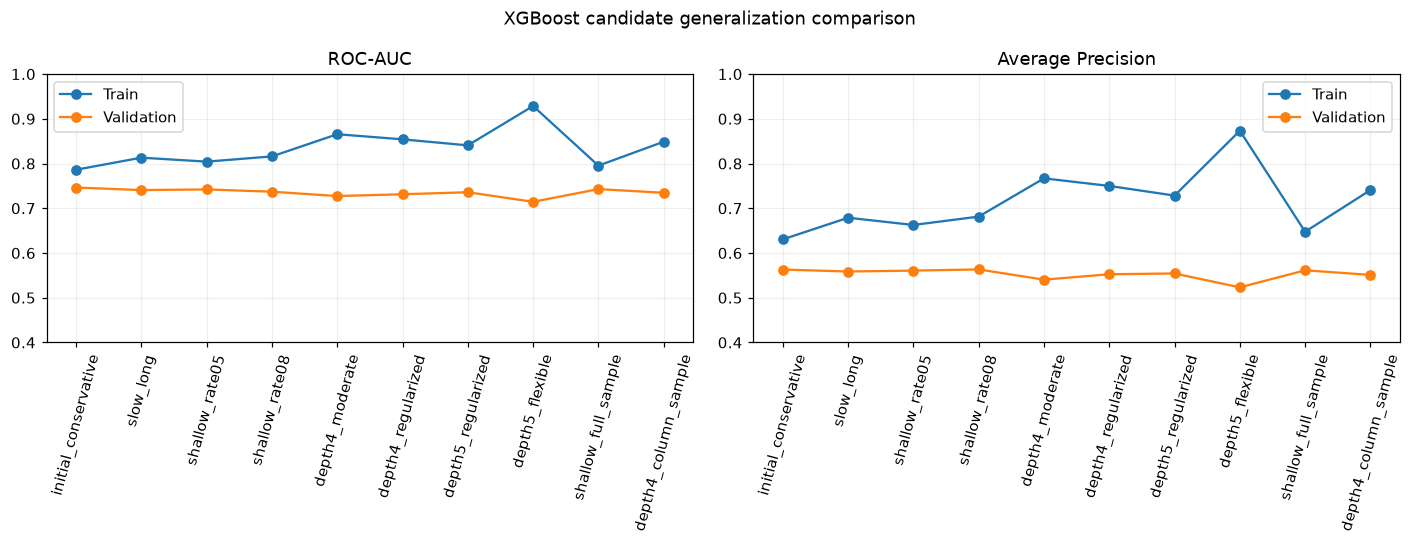

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
positions = np.arange(len(candidate_results))
for ax, train_key, val_key, title in [
    (axes[0], 'train_roc_auc', 'roc_auc', 'ROC-AUC'),
    (axes[1], 'train_average_precision', 'average_precision', 'Average Precision')]:
    ax.plot(positions, candidate_results[train_key], 'o-', label='Train')
    ax.plot(positions, candidate_results[val_key], 'o-', label='Validation')
    ax.set(xticks=positions, xticklabels=candidate_results.name, ylim=(.4, 1), title=title)
    ax.tick_params(axis='x', labelrotation=75)
    ax.legend()
fig.suptitle('XGBoost candidate generalization comparison')
save_figure(fig, 'candidate_train_validation')

## Selected model: full validation metrics and confusion matrix

Average Precision is the same PR-AUC summary used in earlier notebooks. Threshold 0.50 remains diagnostic; no production operating point is chosen.

,selected_xgboost
model,xgboost_unweighted
selected_candidate,initial_conservative
split,validation
threshold,0.5
roc_auc,0.746382
average_precision,0.563016
log_loss,0.551458
brier_score,0.190619
accuracy,0.695971
balanced_accuracy,0.629876


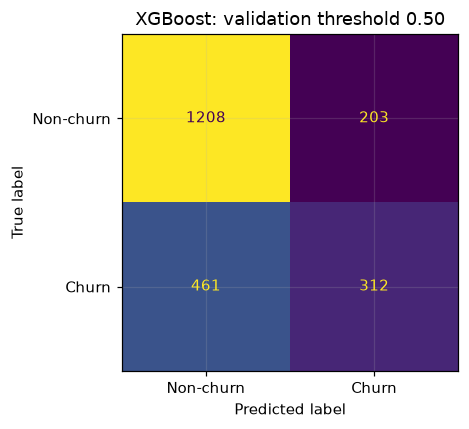

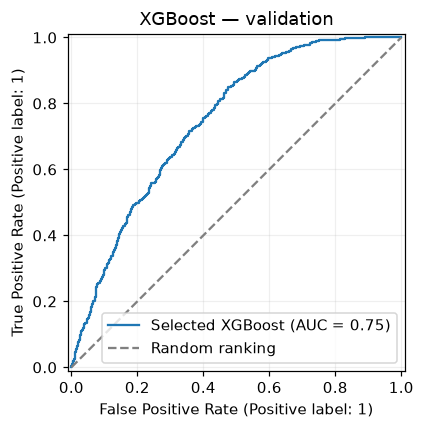

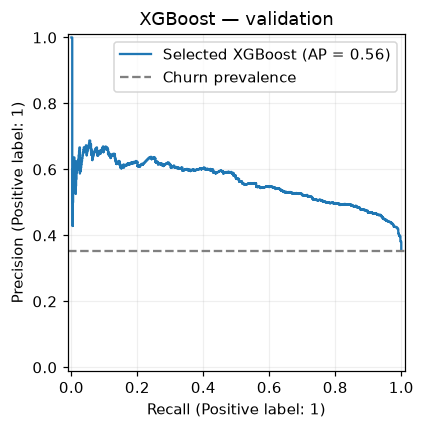

In [5]:
probability = guarded_probabilities(selected, validation, 'validation')
train_probability = guarded_probabilities(selected, train, 'train')
validation_metrics = {**classification_metrics(y_validation, probability), **ranking_metrics(y_validation, probability)}
training_metrics = classification_metrics(y_train, train_probability)
metrics_row = {'model': 'xgboost_unweighted', 'selected_candidate': selected_name, 'split': 'validation',
    'threshold': .5, **validation_metrics, 'train_roc_auc': training_metrics['roc_auc'],
    'train_average_precision': training_metrics['average_precision'],
    'roc_auc_gap': training_metrics['roc_auc'] - validation_metrics['roc_auc'],
    'average_precision_gap': training_metrics['average_precision'] - validation_metrics['average_precision'],
    'mean_predicted_probability': probability.mean(), 'observed_churn_prevalence': y_validation.mean()}
pd.DataFrame([metrics_row]).to_csv(REPORTS/'xgboost_validation_metrics.csv', index=False)
display(pd.Series(metrics_row, name='selected_xgboost').to_frame())
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_validation, probability >= .5, ax=ax,
    display_labels=['Non-churn', 'Churn'], colorbar=False)
ax.set_title('XGBoost: validation threshold 0.50')
save_figure(fig, 'confusion_matrix')
for display_class, name in [(RocCurveDisplay, 'roc'), (PrecisionRecallDisplay, 'precision_recall')]:
    fig, ax = plt.subplots(figsize=(6, 4))
    display_class.from_predictions(y_validation, probability, ax=ax, name='Selected XGBoost')
    if name == 'roc': ax.plot([0,1], [0,1], '--', color='gray', label='Random ranking')
    else: ax.axhline(y_validation.mean(), linestyle='--', color='gray', label='Churn prevalence')
    ax.set_title('XGBoost — validation')
    ax.legend()
    save_figure(fig, name)

## Business ranking, cumulative gains and three-model comparison

Definitions are unchanged: select `ceil(n × fraction)` player-snapshot observations using descending probability and stable input-order ties; labels never break ties. Recall is the proportion of all churn observations captured, precision is churn prevalence among selected rows, and lift divides that precision by full validation prevalence. These are observations, not unique campaign recipients.

Tracked unweighted LR and selected unweighted RF validation metrics are reused at full precision. Difference columns are model minus Logistic Regression; lower Brier and higher other requested metrics are preferred. RF-relative differences are also retained for direct comparison.

,target_fraction,selected_observations,actual_fraction,churn_observations_captured,precision,recall,lift
0,0.1,219,0.100275,135,0.616438,0.174644,1.741658
1,0.2,437,0.200092,261,0.597254,0.337646,1.687455
2,0.3,656,0.300366,382,0.582317,0.494179,1.645253
3,0.4,874,0.400183,476,0.544622,0.615783,1.538752
4,0.5,1092,0.500000,564,0.516484,0.729625,1.459250
5,0.6,1311,0.600275,648,0.494279,0.838292,1.396515
6,0.7,1529,0.700092,712,0.465664,0.921087,1.315666
7,0.8,1748,0.800366,754,0.431350,0.975420,1.218718
8,0.9,1966,0.900183,771,0.392167,0.997413,1.108011
9,1.0,2184,1.000000,773,0.353938,1.000000,1.000000


,Metric,Logistic Regression,Random Forest,XGBoost,Random Forest - Logistic Regression,XGBoost - Logistic Regression,XGBoost - Random Forest
0,roc_auc,0.729547,0.741491,0.746382,0.011944,0.016835,0.004891
1,average_precision,0.534197,0.559362,0.563016,0.025165,0.028819,0.003654
2,brier_score,0.196285,0.191108,0.190619,-0.005177,-0.005666,-0.000489
3,precision,0.547425,0.614118,0.605825,0.066692,0.058400,-0.008292
4,recall,0.261320,0.337646,0.403622,0.076326,0.142303,0.065977
5,f1,0.353765,0.435726,0.484472,0.081961,0.130707,0.048746
6,lift_at_top10pct,1.586844,1.767460,1.741658,0.180616,0.154814,-0.025802
7,recall_at_top10pct,0.159120,0.177232,0.174644,0.018111,0.015524,-0.002587
8,lift_at_top20pct,1.577544,1.719782,1.687455,0.142238,0.109911,-0.032327
9,recall_at_top20pct,0.315653,0.344114,0.337646,0.028461,0.021992,-0.006468


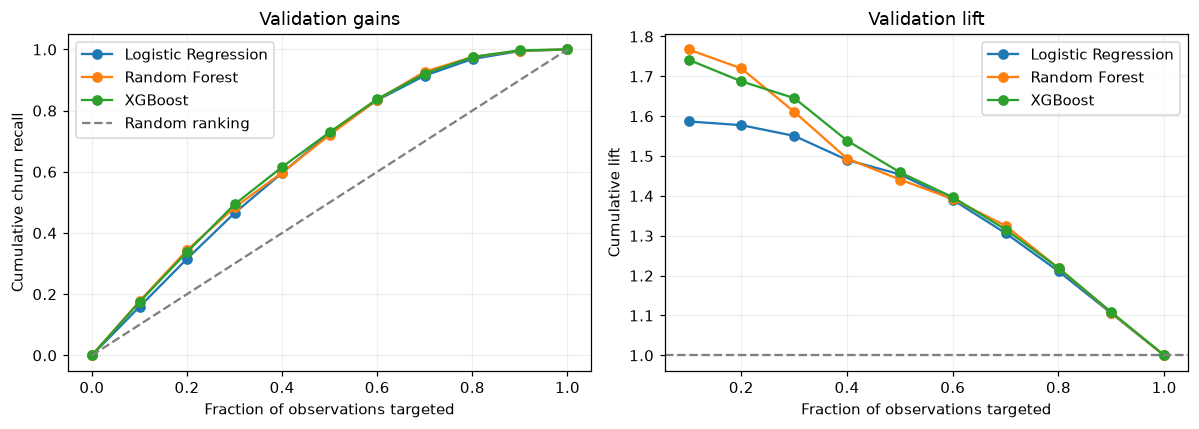

,model,roc_auc_gap,average_precision_gap
0,Random Forest,0.076273,0.126532
1,XGBoost,0.039776,0.067457


In [6]:
gains = cumulative_gains_table(y_validation, probability)
gains.to_csv(REPORTS/'xgboost_validation_cumulative_gains.csv', index=False)
display(gains)
lr_path, rf_path = REPORTS/'logistic_baseline_validation_metrics.csv', REPORTS/'random_forest_validation_metrics.csv'
lr_rows = pd.read_csv(lr_path).query("model == 'logistic_unweighted' and split == 'validation'")
rf_rows = pd.read_csv(rf_path).query("model == 'random_forest_unweighted' and split == 'validation'")
assert len(lr_rows) == len(rf_rows) == 1
lr_metrics, rf_metrics = lr_rows.iloc[0], rf_rows.iloc[0]
comparison_keys = ['roc_auc', 'average_precision', 'brier_score', 'precision', 'recall', 'f1',
                   'lift_at_top10pct', 'recall_at_top10pct', 'lift_at_top20pct', 'recall_at_top20pct']
comparison = pd.DataFrame({'Metric': comparison_keys,
    'Logistic Regression': [lr_metrics[k] for k in comparison_keys],
    'Random Forest': [rf_metrics[k] for k in comparison_keys],
    'XGBoost': [validation_metrics[k] for k in comparison_keys]})
comparison['Random Forest - Logistic Regression'] = comparison['Random Forest'] - comparison['Logistic Regression']
comparison['XGBoost - Logistic Regression'] = comparison['XGBoost'] - comparison['Logistic Regression']
comparison['XGBoost - Random Forest'] = comparison['XGBoost'] - comparison['Random Forest']
comparison.to_csv(REPORTS/'model_validation_comparison.csv', index=False)
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for table, label in [(pd.read_csv(REPORTS/'logistic_baseline_validation_cumulative_gains.csv'), 'Logistic Regression'),
                     (pd.read_csv(REPORTS/'random_forest_validation_cumulative_gains.csv'), 'Random Forest'), (gains, 'XGBoost')]:
    axes[0].plot(np.r_[0, table.actual_fraction], np.r_[0, table.recall], marker='o', label=label)
    axes[1].plot(table.actual_fraction, table.lift, marker='o', label=label)
axes[0].plot([0,1], [0,1], '--', color='gray', label='Random ranking')
axes[0].set(xlabel='Fraction of observations targeted', ylabel='Cumulative churn recall', title='Validation gains')
axes[1].axhline(1, linestyle='--', color='gray')
axes[1].set(xlabel='Fraction of observations targeted', ylabel='Cumulative lift', title='Validation lift')
for ax in axes: ax.legend()
save_figure(fig, 'gains_lift')
gap_comparison = pd.DataFrame([
    {'model': 'Random Forest', 'roc_auc_gap': rf_metrics['roc_auc_gap'], 'average_precision_gap': rf_metrics['average_precision_gap']},
    {'model': 'XGBoost', 'roc_auc_gap': metrics_row['roc_auc_gap'], 'average_precision_gap': metrics_row['average_precision_gap']}])
display(gap_comparison)
gap_comparison.to_csv(REPORTS/'xgboost_generalization_comparison.csv', index=False)

## Threshold table and raw calibration

Validation thresholds 0.20–0.80 are diagnostics only. Reliability compares mean predicted risk with observed churn in quantile bins, reporting row counts. Differences in marginal mean indicate average risk under/overprediction, not by themselves confidence calibration. Probabilities pulled toward the base rate can indicate underconfidence; overly extreme predictions can indicate overconfidence. Reliability deviations may be mixed, and bin estimates are noisy. Brier reflects both discrimination and calibration. No calibration estimator is fitted.

,threshold,precision,recall,f1,specificity,predicted_positives
0,0.2,0.467105,0.918499,0.619276,0.425939,1520
1,0.3,0.492561,0.813713,0.613659,0.540751,1277
2,0.4,0.531250,0.659767,0.588575,0.681077,960
3,0.5,0.605825,0.403622,0.484472,0.856130,515
4,0.6,0.638889,0.119017,0.200654,0.963147,144
5,0.7,1.000000,0.001294,0.002584,1.000000,1
6,0.8,0.000000,0.000000,0.000000,1.000000,0


,observations,mean_predicted_probability,observed_churn_rate
0,219,0.033824,0.009132
1,218,0.077240,0.077982
2,218,0.151451,0.192661
3,219,0.244315,0.292237
4,218,0.325848,0.385321
5,218,0.392348,0.403670
6,219,0.447764,0.433790
7,218,0.493154,0.550459
8,218,0.547331,0.577982
9,219,0.616986,0.616438


Brier 0.1906187339665173 mean probability 0.3330312 observed prevalence 0.35393772893772896


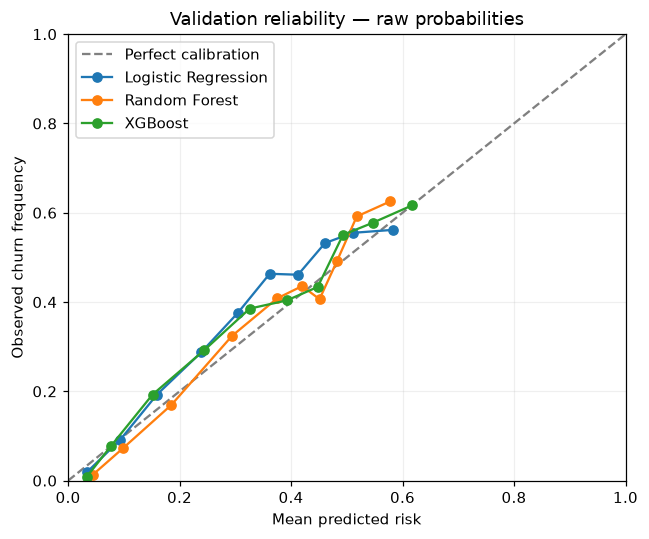

In [7]:
thresholds = threshold_analysis(y_validation, probability)
thresholds.to_csv(REPORTS/'xgboost_validation_thresholds.csv', index=False)
display(thresholds)
observed_bins, predicted_bins = calibration_curve(y_validation, probability, n_bins=10, strategy='quantile')
bin_ids = np.searchsorted(np.percentile(probability, np.linspace(0,100,11))[1:-1], probability)
counts = np.bincount(bin_ids, minlength=10)
nonempty = counts > 0
calibration = pd.DataFrame({'observations': counts[nonempty], 'mean_predicted_probability': predicted_bins,
                            'observed_churn_rate': observed_bins})
assert calibration.observations.sum() == len(validation)
calibration.to_csv(REPORTS/'xgboost_validation_calibration.csv', index=False)
display(calibration)
print('Brier', validation_metrics['brier_score'], 'mean probability', probability.mean(), 'observed prevalence', y_validation.mean())
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0,1], [0,1], '--', color='gray', label='Perfect calibration')
for table, xkey, label in [
    (pd.read_csv(REPORTS/'logistic_baseline_validation_calibration.csv'), 'mean_probability', 'Logistic Regression'),
    (pd.read_csv(REPORTS/'random_forest_validation_calibration.csv'), 'mean_predicted_probability', 'Random Forest'),
    (calibration, 'mean_predicted_probability', 'XGBoost')]:
    ax.plot(table[xkey], table.observed_churn_rate, marker='o', label=label)
ax.set(xlabel='Mean predicted risk', ylabel='Observed churn frequency', title='Validation reliability — raw probabilities', xlim=(0,1), ylim=(0,1))
ax.legend()
save_figure(fig, 'calibration')

## Interpretation: gain reference and validation permutation

Built-in gain importance summarizes mean training split gain for each transformed feature (normalized by XGBoost). Transformed names expose one-hot levels and missingness indicators; unsplit features receive zero. Gain is a training reference and can favor features with more split opportunities.

Preferred comparison uses validation permutation Average Precision drop on the original predictor frame through the fitted pipeline, five repeats, seed 42. Categorical dummies stay together, and numeric values move with their derived missingness flags. We use all validation rows with sequential permutations to avoid nested parallelism; the fitted model retains `n_jobs=-1`. Repeat standard deviations describe permutation variability, not population confidence intervals. Correlated predictors can share or mask importance, and independent shuffling can create unrealistic combinations. Importance is predictive reliance, **not causation**. SHAP is deferred until final family selection.

### Top 20 transformed gain features (reference)

,feature,normalized_gain
16,numeric__winnings_7d,0.226527
8,numeric__days_since_last_active_bet,0.071583
15,numeric__winnings_14d,0.051945
35,numeric__active_days_recent15,0.045306
0,numeric__active_days_30d,0.038361
4,numeric__active_days_7d,0.037593
43,numeric__missingindicator_max_gap_between_acti...,0.031714
38,numeric__active_days_change_pct_15d,0.031088
2,numeric__active_days_14d,0.030220
14,numeric__winnings_30d,0.021382


Permutation seconds: 6.6


### Top 20 original predictors: validation permutation

,feature,mean_ap_drop,std_ap_drop
8,days_since_last_active_bet,0.033656,0.003091
16,winnings_7d,0.012255,0.004313
0,active_days_30d,0.011194,0.006104
41,days_since_first_casino_activity,0.010435,0.001925
21,max_daily_stake_30d,0.005046,0.001192
40,days_since_first_pay,0.004230,0.001684
23,std_daily_stake_30d,0.003557,0.001350
35,active_days_recent15,0.003097,0.003161
11,stake_30d,0.002810,0.002300
10,mean_gap_between_active_days_30d,0.002773,0.001737


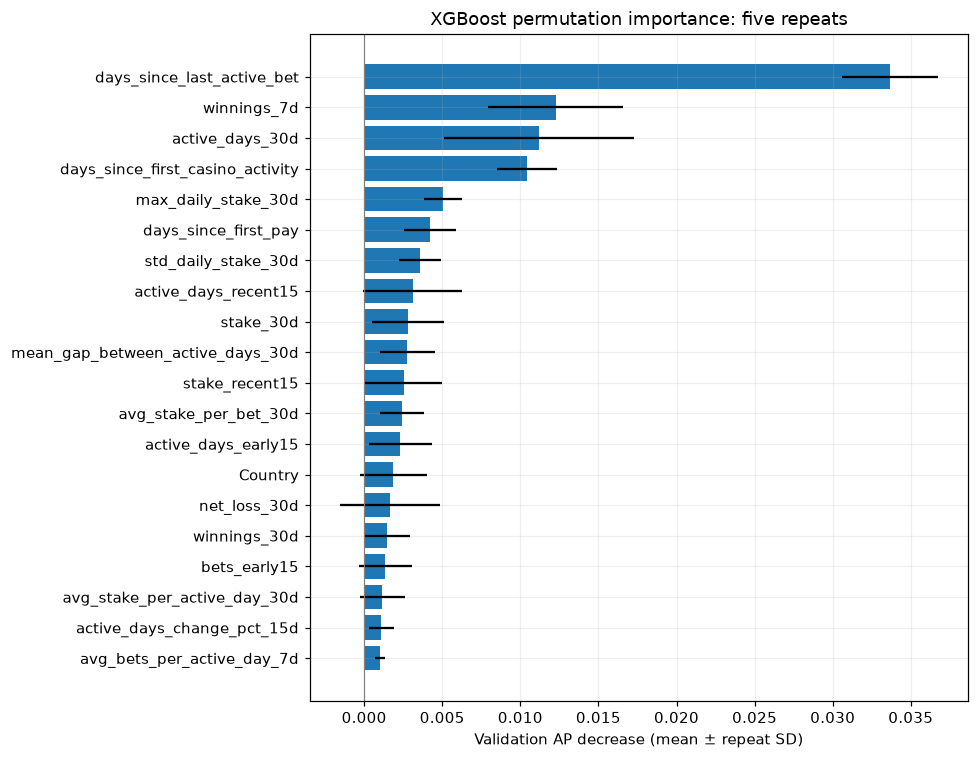

In [8]:
gain = pd.DataFrame({'feature': selected['preprocessing'].get_feature_names_out(),
                     'normalized_gain': selected['model'].feature_importances_}).sort_values('normalized_gain', ascending=False)
assert len(gain) == len(selected['preprocessing'].get_feature_names_out())
gain.to_csv(REPORTS/'xgboost_gain_importance.csv', index=False)
display(Markdown('### Top 20 transformed gain features (reference)'))
display(gain.head(20))
start = time.perf_counter()
permuted = permutation_importance(selected, X_validation, y_validation, scoring='average_precision',
                                 n_repeats=5, random_state=42, n_jobs=1)
permutation = pd.DataFrame({'feature': X_validation.columns, 'mean_ap_drop': permuted.importances_mean,
                           'std_ap_drop': permuted.importances_std}).sort_values('mean_ap_drop', ascending=False)
permutation.to_csv(REPORTS/'xgboost_permutation_importance.csv', index=False)
print('Permutation seconds:', round(time.perf_counter()-start,1))
display(Markdown('### Top 20 original predictors: validation permutation'))
display(permutation.head(20))
top = permutation.head(20).sort_values('mean_ap_drop')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.feature, top.mean_ap_drop, xerr=top.std_ap_drop)
ax.axvline(0, color='gray', linewidth=.8)
ax.set(xlabel='Validation AP decrease (mean ± repeat SD)', title='XGBoost permutation importance: five repeats')
save_figure(fig, 'permutation_importance')

## Validation errors and comparison with RF

At threshold 0.50, group outcomes are TP/FP/TN/FN. Counts, feature medians and nonmissing counts describe groups, without exporting player-level probabilities. Trend ratios retain raw missingness for these summaries. Similar medians can reveal difficult separation, but do not establish why any individual churned or was misclassified.

In [9]:
positive, actual = probability >= .5, y_validation.to_numpy() == 1
outcomes = np.select([actual & positive, ~actual & positive, ~actual & ~positive, actual & ~positive],
                     ['TP','FP','TN','FN'], default='unknown')
error_features = ['days_since_last_active_bet', 'active_days_30d', 'bets_30d', 'stake_30d',
                  'bets_change_pct_15d', 'active_days_change_15d']
descriptive = validation[error_features].assign(outcome=outcomes)
error_counts = descriptive.groupby('outcome').size().reindex(['TP','FP','TN','FN'], fill_value=0)
error_medians = descriptive.groupby('outcome')[error_features].median().reindex(['TP','FP','TN','FN'])
error_nonmissing = descriptive.groupby('outcome')[error_features].count().reindex(['TP','FP','TN','FN'], fill_value=0)
error_summary = error_medians.assign(observations=error_counts)
error_summary.to_csv(REPORTS/'xgboost_error_group_medians.csv')
error_nonmissing.to_csv(REPORTS/'xgboost_error_group_nonmissing_counts.csv')
display(error_summary)
display(error_nonmissing)
rf_errors = pd.read_csv(REPORTS/'random_forest_error_group_medians.csv', index_col='outcome').reindex(['TP','FP','TN','FN'])
error_comparison = pd.concat({'Random Forest': rf_errors, 'XGBoost': error_summary}, names=['model', 'outcome'])
error_comparison.to_csv(REPORTS/'xgboost_rf_error_comparison.csv')
display(error_comparison)
del descriptive

,days_since_last_active_bet,active_days_30d,bets_30d,stake_30d,bets_change_pct_15d,active_days_change_15d,observations
outcome,,,,,,,
TP,20.0,1.0,5.5,28.50,-100.000000,-1.0,312
FP,19.0,1.0,5.0,31.90,-100.000000,-1.0,203
TN,3.0,4.0,106.0,1054.50,-48.245614,0.0,1208
FN,9.0,2.0,46.0,231.34,-100.000000,0.0,461


,days_since_last_active_bet,active_days_30d,bets_30d,stake_30d,bets_change_pct_15d,active_days_change_15d
outcome,,,,,,
TP,312,312,312,312,247,312
FP,203,203,203,203,151,203
TN,1208,1208,1208,1208,891,1208
FN,461,461,461,461,286,461


days_since_last_active_bet  active_days_30d  bets_30d  \
model         outcome                                                          
Random Forest TP                             20.0              1.0       4.0   
              FP                             19.0              1.0       4.0   
              TN                              3.0              4.0     100.0   
              FN                             10.0              2.0      44.0   
XGBoost       TP                             20.0              1.0       5.5   
              FP                             19.0              1.0       5.0   
              TN                              3.0              4.0     106.0   
              FN                              9.0              2.0      46.0   

                       stake_30d  bets_change_pct_15d  active_days_change_15d  \
model         outcome                                                           
Random Forest TP           20.00          -100.000000                    -1.0   
              FP           20.50          -100.000000                    -1.0   
              TN          993.10           -52.132571                     0.0   
              FN          197.00          -100.000000                     0.0   
XGBoost       TP           28.50          -100.000000                    -1.0   
              FP           31.90          -100.000000                    -1.0   
              TN         1054.50           -48.245614                     0.0   
              FN          231.34          -100.000000                     0.0   

                       observations  
model         outcome                
Random Forest TP                261  
              FP                164  
              TN               1247  
              FN                512  
XGBoost       TP                312  
              FP                203  
              TN               1208  
              FN                461

## Provisional recommendation, dependence and validation optimism

Validation has now supported feature/model comparisons, RF candidate selection and XGBoost candidate selection. This reuse introduces **validation-selection optimism**, even with a small documented search. No reported improvement is a statistically established population difference. Do not interpret one metric as sufficient to choose the family.

Repeated-player overlap across dates is intentional because production repeatedly scores existing players. UserID is excluded, but behavioral continuity and multiple rows per player remain dependent. The primary temporal split stays unchanged. Later player-clustered uncertainty estimates or unseen-player sensitivity could assess robustness without replacing the operational evaluation or opening test.

The family recommendation below follows the declared ranking-first rule, uses generalization and Brier to resolve near ties, and documents remaining risks. Calibration and any cost/capacity-based threshold must be planned using only open development data before one final locked test evaluation. No test evaluation is authorized by this notebook.

In [10]:
family_rows = []
for name, row in [('Logistic Regression', lr_metrics), ('Random Forest', rf_metrics), ('XGBoost', metrics_row)]:
    family_rows.append({'family': name, **{k: row[k] for k in comparison_keys},
                       'average_precision_gap': row.get('average_precision_gap', np.nan)})
families = pd.DataFrame(family_rows)
eligible = families.copy()
for key, tolerance in [('average_precision',.002), ('roc_auc',.002),
                       ('lift_at_top10pct',.02), ('recall_at_top10pct',.002)]:
    eligible = eligible.loc[eligible[key] >= eligible[key].max()-tolerance]
if eligible.average_precision_gap.notna().any():
    minimum_gap = eligible.average_precision_gap.min()
    eligible = eligible.loc[eligible.average_precision_gap.isna() | (eligible.average_precision_gap <= minimum_gap+.02)]
eligible = eligible.loc[eligible.brier_score <= eligible.brier_score.min()+.002]
family_order = ['Logistic Regression', 'Random Forest', 'XGBoost']
recommended_family = min(eligible.family, key=family_order.index)
leaders = {k: families.set_index('family')[k].idxmin() if k == 'brier_score' else families.set_index('family')[k].idxmax()
           for k in ['roc_auc','average_precision','lift_at_top10pct','brier_score']}
display(families)
print('Metric leaders:', leaders)
print('Provisional recommended family:', recommended_family)
roc_gap_change = metrics_row['roc_auc_gap'] - rf_metrics['roc_auc_gap']
ap_gap_change = metrics_row['average_precision_gap'] - rf_metrics['average_precision_gap']
if abs(roc_gap_change) <= .01 and abs(ap_gap_change) <= .02: generalization = 'similarly'
elif roc_gap_change < 0 and ap_gap_change < 0: generalization = 'better'
elif roc_gap_change > 0 and ap_gap_change > 0: generalization = 'worse'
else: generalization = 'with mixed gap evidence'
selected_parameters = {k: selected['model'].get_params()[k] for k in PARAMETER_COLUMNS}
joblib.dump(selected, MODELS/'xgboost_model.joblib')
reloaded = joblib.load(MODELS/'xgboost_model.joblib')
np.testing.assert_allclose(probability, guarded_probabilities(reloaded, validation, 'validation'), rtol=0, atol=1e-7)
del reloaded
metadata = {'selected_candidate': selected_name, 'parameters': selected['model'].get_params(),
    'recommended_family': recommended_family, 'data_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'baseline_metrics_sha256': hashlib.sha256(lr_path.read_bytes()).hexdigest(),
    'rf_metrics_sha256': hashlib.sha256(rf_path.read_bytes()).hexdigest(),
    'python': platform.python_version(), 'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__, 'permutation_scoring': 'average_precision',
    'permutation_repeats': 5, 'random_state': 42, 'test_predictions_generated': False,
    'calibrated': False, 'production_threshold_selected': False, 'shap_computed': False}
# Record the missing-value sentinel as text so the audit artifact is strict JSON.
metadata['parameters']['missing'] = 'NaN'
(REPORTS/'xgboost_run_metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False), encoding='utf-8')
summary_lines = [f'# Day 8 XGBoost: {selected_name}',
    'Configuration: ' + ', '.join(f'{k}={v}' for k,v in selected_parameters.items()) + '; random_state=42, n_jobs=-1, objective=binary:logistic, eval_metric=logloss, tree_method=hist.',
    f"Train ROC-AUC {training_metrics['roc_auc']:.4f}; PR-AUC/AP {training_metrics['average_precision']:.4f}.",
    f"Validation ROC-AUC {validation_metrics['roc_auc']:.4f}; PR-AUC/AP {validation_metrics['average_precision']:.4f}; Brier {validation_metrics['brier_score']:.4f}.",
    f"At diagnostic threshold 0.50: precision {validation_metrics['precision']:.4f}; recall {validation_metrics['recall']:.4f}; F1 {validation_metrics['f1']:.4f}.",
    f"Top10%: precision {validation_metrics['precision_at_top10pct']:.4f}; recall {validation_metrics['recall_at_top10pct']:.2%}; lift {validation_metrics['lift_at_top10pct']:.4f}.",
    f"Top20%: precision {validation_metrics['precision_at_top20pct']:.4f}; recall {validation_metrics['recall_at_top20pct']:.2%}; lift {validation_metrics['lift_at_top20pct']:.4f}.",
    f"Train-validation gaps: ROC-AUC {metrics_row['roc_auc_gap']:.4f}; AP {metrics_row['average_precision_gap']:.4f}. RF gaps are {rf_metrics['roc_auc_gap']:.4f} and {rf_metrics['average_precision_gap']:.4f}. XGBoost generalizes {generalization} by these resubstitution-gap diagnostics (similarity tolerances: 0.01 ROC, 0.02 AP); temporal drift also contributes.",
    'Metric leaders: ' + '; '.join(f'{k}: {v}' for k,v in leaders.items()) + '.',
    'Differences XGBoost minus Logistic Regression: ' + '; '.join(f"{row['Metric']} {row['XGBoost - Logistic Regression']:+.4f}" for _,row in comparison.iterrows()) + '.',
    'Differences XGBoost minus Random Forest: ' + '; '.join(f"{row['Metric']} {row['XGBoost - Random Forest']:+.4f}" for _,row in comparison.iterrows()) + '. Lower Brier is better.',
    'Top five validation permutation predictors: ' + ', '.join(permutation.head(5).feature) + '. Correlated features may share or mask predictive importance; repeat SD is not population uncertainty and importance is not causal.',
    f"Error analysis: XGB TP/FP median recency {error_medians.loc['TP','days_since_last_active_bet']:.0f}/{error_medians.loc['FP','days_since_last_active_bet']:.0f} days (RF {rf_errors.loc['TP','days_since_last_active_bet']:.0f}/{rf_errors.loc['FP','days_since_last_active_bet']:.0f}); XGB TP/FP median active days {error_medians.loc['TP','active_days_30d']:.0f}/{error_medians.loc['FP','active_days_30d']:.0f} (RF {rf_errors.loc['TP','active_days_30d']:.0f}/{rf_errors.loc['FP','active_days_30d']:.0f}). XGB FN/TN median recency {error_medians.loc['FN','days_since_last_active_bet']:.0f}/{error_medians.loc['TN','days_since_last_active_bet']:.0f}, bets {error_medians.loc['FN','bets_30d']:.0f}/{error_medians.loc['TN','bets_30d']:.0f} (RF recency {rf_errors.loc['FN','days_since_last_active_bet']:.0f}/{rf_errors.loc['TN','days_since_last_active_bet']:.0f}, bets {rf_errors.loc['FN','bets_30d']:.0f}/{rf_errors.loc['TN','bets_30d']:.0f}). These are descriptive groups, not individual explanations.",
    f"Calibration: mean predicted risk {probability.mean():.2%}, observed churn {y_validation.mean():.2%}, Brier {validation_metrics['brier_score']:.4f}. " + ('Average risk is underpredicted.' if probability.mean() < y_validation.mean() else 'Average risk is overpredicted.') + f" Lowest-risk bin: predicted {predicted_bins[0]:.2%}, observed {observed_bins[0]:.2%}; highest-risk bin: predicted {predicted_bins[-1]:.2%}, observed {observed_bins[-1]:.2%}. Middle-bin deviations can differ; the mean alone does not establish under/overconfidence. Raw reliability and Brier need review before calibration.",
    f"Reliability interpretation: observed churn exceeds predicted risk in {int((observed_bins > predicted_bins).sum())} of {len(observed_bins)} bins. Risk is especially underpredicted in several middle bins, while the highest-risk bin is close to the diagonal. The lowest-risk bin overpredicts churn. This is mixed miscalibration, rather than uniform underconfidence or overconfidence. XGB's mean is farther below prevalence than RF's {rf_metrics['mean_predicted_probability']:.2%}, despite a slightly lower Brier score; Brier alone does not establish superior calibration.",
    f"Provisional model-family recommendation: **{recommended_family}** under the predeclared AP/ROC/business-ranking rule, using generalization gaps and Brier to resolve near ties. This is a development recommendation, not a test-validated final winner.",
    f"The XGB-versus-RF AP difference is {validation_metrics['average_precision']-rf_metrics['average_precision']:+.4f}, a modest advantage whose robustness has not been established. RF retains stronger top10/top20 lift and capture, whereas XGB has higher overall ROC-AUC/AP, smaller resubstitution gaps and slightly lower Brier. These results support a provisional overall XGB choice under the stated priorities; a fixed campaign capacity may favor RF. Do not claim statistical superiority or select an operational policy from these diagnostics.",
    'Limitations: validation-selection optimism, one temporal validation window, repeated-player dependence, correlated features and uncalibrated probabilities. The primary split is unchanged. No SHAP or operational threshold has been selected.',
    'The model is saved locally to Git-ignored models/xgboost_model.joblib. Only aggregate tables/figures are tracked. Test remains sealed; the recommendation is provisional until one final locked test-set evaluation. No commit or push.']
summary_text = '\n\n'.join(summary_lines)
display(Markdown(summary_text))
(REPORTS/'xgboost_summary.md').write_text(summary_text, encoding='utf-8')

,family,roc_auc,average_precision,brier_score,precision,recall,f1,lift_at_top10pct,recall_at_top10pct,lift_at_top20pct,recall_at_top20pct,average_precision_gap
0,Logistic Regression,0.729547,0.534197,0.196285,0.547425,0.261320,0.353765,1.586844,0.159120,1.577544,0.315653,NaN
1,Random Forest,0.741491,0.559362,0.191108,0.614118,0.337646,0.435726,1.767460,0.177232,1.719782,0.344114,0.126532
2,XGBoost,0.746382,0.563016,0.190619,0.605825,0.403622,0.484472,1.741658,0.174644,1.687455,0.337646,0.067457


Metric leaders: {'roc_auc': 'XGBoost', 'average_precision': 'XGBoost', 'lift_at_top10pct': 'Random Forest', 'brier_score': 'XGBoost'}
Provisional recommended family: XGBoost


# Day 8 XGBoost: initial_conservative

Configuration: n_estimators=400, learning_rate=0.03, max_depth=3, min_child_weight=10, subsample=0.8, colsample_bytree=0.9, reg_lambda=10, reg_alpha=0.1, gamma=0.1; random_state=42, n_jobs=-1, objective=binary:logistic, eval_metric=logloss, tree_method=hist.

Train ROC-AUC 0.7862; PR-AUC/AP 0.6305.

Validation ROC-AUC 0.7464; PR-AUC/AP 0.5630; Brier 0.1906.

At diagnostic threshold 0.50: precision 0.6058; recall 0.4036; F1 0.4845.

Top10%: precision 0.6164; recall 17.46%; lift 1.7417.

Top20%: precision 0.5973; recall 33.76%; lift 1.6875.

Train-validation gaps: ROC-AUC 0.0398; AP 0.0675. RF gaps are 0.0763 and 0.1265. XGBoost generalizes better by these resubstitution-gap diagnostics (similarity tolerances: 0.01 ROC, 0.02 AP); temporal drift also contributes.

Metric leaders: roc_auc: XGBoost; average_precision: XGBoost; lift_at_top10pct: Random Forest; brier_score: XGBoost.

Differences XGBoost minus Logistic Regression: roc_auc +0.0168; average_precision +0.0288; brier_score -0.0057; precision +0.0584; recall +0.1423; f1 +0.1307; lift_at_top10pct +0.1548; recall_at_top10pct +0.0155; lift_at_top20pct +0.1099; recall_at_top20pct +0.0220.

Differences XGBoost minus Random Forest: roc_auc +0.0049; average_precision +0.0037; brier_score -0.0005; precision -0.0083; recall +0.0660; f1 +0.0487; lift_at_top10pct -0.0258; recall_at_top10pct -0.0026; lift_at_top20pct -0.0323; recall_at_top20pct -0.0065. Lower Brier is better.

Top five validation permutation predictors: days_since_last_active_bet, winnings_7d, active_days_30d, days_since_first_casino_activity, max_daily_stake_30d. Correlated features may share or mask predictive importance; repeat SD is not population uncertainty and importance is not causal.

Error analysis: XGB TP/FP median recency 20/19 days (RF 20/19); XGB TP/FP median active days 1/1 (RF 1/1). XGB FN/TN median recency 9/3, bets 46/106 (RF recency 10/3, bets 44/100). These are descriptive groups, not individual explanations.

Calibration: mean predicted risk 33.30%, observed churn 35.39%, Brier 0.1906. Average risk is underpredicted. Lowest-risk bin: predicted 3.38%, observed 0.91%; highest-risk bin: predicted 61.70%, observed 61.64%. Middle-bin deviations can differ; the mean alone does not establish under/overconfidence. Raw reliability and Brier need review before calibration.

Reliability interpretation: observed churn exceeds predicted risk in 7 of 10 bins. Risk is especially underpredicted in several middle bins, while the highest-risk bin is close to the diagonal. The lowest-risk bin overpredicts churn. This is mixed miscalibration, rather than uniform underconfidence or overconfidence. XGB's mean is farther below prevalence than RF's 34.48%, despite a slightly lower Brier score; Brier alone does not establish superior calibration.

Provisional model-family recommendation: **XGBoost** under the predeclared AP/ROC/business-ranking rule, using generalization gaps and Brier to resolve near ties. This is a development recommendation, not a test-validated final winner.

The XGB-versus-RF AP difference is +0.0037, a modest advantage whose robustness has not been established. RF retains stronger top10/top20 lift and capture, whereas XGB has higher overall ROC-AUC/AP, smaller resubstitution gaps and slightly lower Brier. These results support a provisional overall XGB choice under the stated priorities; a fixed campaign capacity may favor RF. Do not claim statistical superiority or select an operational policy from these diagnostics.

Limitations: validation-selection optimism, one temporal validation window, repeated-player dependence, correlated features and uncalibrated probabilities. The primary split is unchanged. No SHAP or operational threshold has been selected.

The model is saved locally to Git-ignored models/xgboost_model.joblib. Only aggregate tables/figures are tracked. Test remains sealed; the recommendation is provisional until one final locked test-set evaluation. No commit or push.

4022